In [1]:
# Initialize Otter
import otter
grader = otter.Notebook("hw5.ipynb")

# CPSC 330 - Applied Machine Learning 

## Homework 5: Putting it all together 
### Associated lectures: All material till lecture 13 

<div class="alert-warning">
    
## Instructions  
rubric={points}

You will earn points for following these instructions and successfully submitting your work on Gradescope.  

### Before you start  

- Please **read carefully
[Use of Generative AI policy](https://ubc-cs.github.io/cpsc330-2025W1/syllabus.html#use-of-generative-ai-in-the-course)** before starting the homework assignment. 
  
- Review the [CPSC 330 homework instructions](https://ubc-cs.github.io/cpsc330-2025W1/docs/homework_instructions.html) for detailed guidance on completing and submitting assignments. 

### Group work instructions

**You may work with a partner on this homework and submit your assignment as a group.** Below are some instructions on working as a group.  
- The maximum group size is 2.
  
- Use group work as an opportunity to collaborate and learn new things from each other. 
- Be respectful to each other and make sure you understand all the concepts in the assignment well. 
- It's your responsibility to make sure that the assignment is submitted by one of the group members before the deadline. 
- You can find the instructions on how to do group submission on Gradescope [here](https://help.gradescope.com/article/m5qz2xsnjy-student-add-group-members).
- If you would like to use late tokens for the homework, all group members must have the necessary late tokens available. Please note that the late tokens will be counted for all members of the group.   
### Before submitting  

- **Run all cells** (▶▶ button) to ensure the notebook executes cleanly from top to bottom.

  - Execution counts must start at **1** and be sequential.
    
  - Notebooks with missing outputs or errors may lose marks.

- **Do not upload or push data files** used in this lab to GitHub or Gradescope. (A `.gitignore` is provided to prevent this.)  


### Submitting on Gradescope  

- Upload **only** your `.ipynb` file (with outputs shown) and any required output files. Do **not** submit extra files.
  
- If needed, refer to the [Gradescope Student Guide](https://lthub.ubc.ca/guides/gradescope-student-guide/).  
- If your notebook is too large to render, also upload a **Web PDF** or **HTML** version.  
  - You can create one using **File $\rightarrow$ Save and Export Notebook As**.  
  - If you get an error when creating a PDF, try running the following commands in your lab directory:  

    ```bash
    conda install -c conda-forge nbconvert-playwright
    jupyter nbconvert --to webpdf lab1.ipynb
    ```  

  - Ensure all outputs are visible in your PDF or HTML file; TAs cannot grade your work if outputs are missing.

</div>


_Note: Unlike previous assignments, this one is open-ended and project-style. Treat it as an opportunity to explore, experiment, and learn._

<!-- BEGIN QUESTION -->

## Imports

<div class="alert alert-warning">
    
Imports
    
</div>

_Points:_ 0

In [2]:
from hashlib import sha1 

import matplotlib.pyplot as plt 
import numpy as np 
import pandas as pd 

from sklearn.model_selection import cross_val_score, cross_validate, train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer, make_column_transformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_extraction.text import CountVectorizer 
from sklearn.pipeline import Pipeline, make_pipeline

from sklearn.dummy import DummyRegressor 
from sklearn.metrics import mean_absolute_error

from sklearn.linear_model import Ridge 

from sklearn.metrics import mean_squared_error, r2_score, make_scorer, root_mean_squared_error

<!-- END QUESTION -->

## Introduction

In this homework you will be working on an open-ended mini-project, where you will put all the different things you have learned so far together to solve an interesting problem.

A few notes and tips when you work on this mini-project: 

#### Tips
1. This mini-project is open-ended, and while working on it, there might be some situations where you'll have to use your own judgment and make your own decisions (as you would be doing when you work as a data scientist). Make sure you explain your decisions whenever necessary. 
2. **Do not include everything you ever tried in your submission** -- it's fine just to have your final code. That said, your code should be reproducible and well-documented. For example, if you chose your hyperparameters based on some hyperparameter optimization experiment, you should leave in the code for that experiment so that someone else could re-run it and obtain the same hyperparameters, rather than mysteriously just setting the hyperparameters to some (carefully chosen) values in your code. 
3. If you realize that you are repeating a lot of code try to organize it in functions. Clear presentation of your code, experiments, and results is the key to be successful in this lab. You may use code from lecture notes or previous lab solutions with appropriate attributions. 

#### Assessment
We plan to grade fairly and leniently. We don't have some secret target score that you need to achieve to get a good grade. **You'll be assessed on demonstration of mastery of course topics, clear presentation, and the quality of your analysis and results.** For example, if you just have a bunch of code and no text or figures, that's not good. If you do a bunch of sane things and get a lower accuracy than your friend, don't sweat it.


#### A final note
Finally, this style of this "project" question is different from other assignments. It'll be up to you to decide when you're "done" -- in fact, this is one of the hardest parts of real projects. But please don't spend WAY too much time on this... perhaps "a few hours" (10-14 hours???) is a good guideline for this project . Of course if you're having fun you're welcome to spend as much time as you want! But, if so, try not to do it out of perfectionism or getting the best possible grade. Do it because you're learning and enjoying it. Students from the past cohorts have found such kind of labs useful and fun and I hope you enjoy it as well. 

<br><br>

<!-- BEGIN QUESTION -->

## 1. Pick your problem and explain the prediction problem
<hr>
rubric={points:3}

In this mini project, you have the option to choose on which dataset you will be working on. The tasks you will need to carry on will be similar, independently of your choice.

### Option 1
You can choose to work on a classification problem of predicting whether a credit card client will default or not. 
For this problem, you will use [Default of Credit Card Clients Dataset](https://www.kaggle.com/uciml/default-of-credit-card-clients-dataset). In this data set, there are 30,000 examples and 24 features, and the goal is to estimate whether a person will default (fail to pay) their credit card bills; this column is labeled "default.payment.next.month" in the data. The rest of the columns can be used as features. You may take some ideas and compare your results with [the associated research paper](https://www.sciencedirect.com/science/article/pii/S0957417407006719), which is available through [the UBC library](https://www.library.ubc.ca/). 


### Option 2
You can choose to work on a regression problem using a [dataset](https://www.kaggle.com/dgomonov/new-york-city-airbnb-open-data) of New York City Airbnb listings from 2019. As usual, you'll need to start by downloading the dataset, then you will try to predict `reviews_per_month`, as a proxy for the popularity of the listing. Airbnb could use this sort of model to predict how popular future listings might be before they are posted, perhaps to help guide hosts create more appealing listings. In reality they might instead use something like vacancy rate or average rating as their target, but we do not have that available here.

> Note there is an updated version of this dataset with more features available [here](http://insideairbnb.com/). The features were are using in `listings.csv.gz` for the New York city datasets. You will also see some other files like `reviews.csv.gz`. For your own interest you may want to explore the expanded dataset and try your analysis there. However, please submit your results on the dataset obtained from Kaggle.


<div class="alert alert-info">
    
**Your tasks:**

1. Review the available datasets and choose the one you find most interesting. It may help to read through the dataset documentation on Kaggle before deciding.
2. Once you've selected a dataset, take time to understand the problem it represents and the meaning of each feature. Use the Kaggle documentation to guide you.
3. Download the dataset and load it into a pandas DataFrame.
4. Write a few sentences summarizing your initial thoughts about the problem and the dataset.
   
</div>

<div class="alert alert-warning">
    
Solution_1
    
</div>

_Points:_ 3

_Type your answer here, replacing this text._

In [3]:
airbnb_df = pd.read_csv("data/AB_NYC_2019.csv")
airbnb_df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48890,36484665,Charming one bedroom - newly renovated rowhouse,8232441,Sabrina,Brooklyn,Bedford-Stuyvesant,40.67853,-73.94995,Private room,70,2,0,NaN,NaN,2,9
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27
48893,36485609,43rd St. Time Square-cozy single bed,30985759,Taz,Manhattan,Hell's Kitchen,40.75751,-73.99112,Shared room,55,1,0,NaN,NaN,6,2


In [4]:
airbnb_df.shape

(48895, 16)

The New York City Airbnb listings dataset from 2019 provides valuable information for predicting the popularity of listings. It includes details such as the listing name, host information, neighbourhood characteristics, property details and review activity. The goal is to predict the reviews_per_month, which serves as a proxy for a listing's popularity. At first glance, the dataset contains missing values that will require imputation, as well as categorical variables that need to be encoded into numerical features before modelling. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 2. Data splitting
<hr>
rubric={points:2}

<div class="alert alert-info">
    
**Your tasks:**

1. Split the data into train (70%) and test (30%) portions with `random_state=123`.

> If your computer cannot handle training on 70% training data, make the test split bigger.

</div>

<div class="alert alert-warning">
    
Solution_2
    
</div>

_Points:_ 2

In [5]:
train_df = None
test_df = None

train_df, test_df = train_test_split(airbnb_df, test_size = 0.3, random_state = 123)

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 3. EDA
<hr>
rubric={points:10}

<div class="alert alert-info">

**Your tasks:**

1. **Perform exploratory data analysis (EDA)**: Conduct an initial exploration of the training set to better understand its characteristics.

2. **Summarize and visualize the data**: Include at least **two summary statistics** and **two visualizations** that you find informative. For each, write **one sentence** explaining what insight it provides.

3. **Record your observations**: Summarize your **initial observations** about the dataset based on your EDA.

4. **Select evaluation metrics**: Choose one or more **appropriate metrics** for assessing model performance and briefly justify your choice.

</div>

<div class="alert alert-warning">
    
Solution_3
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [6]:
train_df.sort_index()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0
6,5121,BlissArtsSpace!,7356,Garon,Brooklyn,Bedford-Stuyvesant,40.68688,-73.95596,Private room,60,45,49,2017-10-05,0.40,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
48888,36484087,"Spacious Room w/ Private Rooftop, Central loca...",274321313,Kat,Manhattan,Hell's Kitchen,40.76392,-73.99183,Private room,125,4,0,NaN,NaN,1,31
48889,36484363,QUIT PRIVATE HOUSE,107716952,Michael,Queens,Jamaica,40.69137,-73.80844,Private room,65,1,0,NaN,NaN,2,163
48891,36485057,Affordable room in Bushwick/East Williamsburg,6570630,Marisol,Brooklyn,Bushwick,40.70184,-73.93317,Private room,40,4,0,NaN,NaN,2,36
48892,36485431,Sunny Studio at Historical Neighborhood,23492952,Ilgar & Aysel,Manhattan,Harlem,40.81475,-73.94867,Entire home/apt,115,10,0,NaN,NaN,1,27


We observe that name, host_name, neighbourhood_group, neighbourhood, and room_type are categorical features. last_review is a date feature. The columns latitude, longitude, price, minimum_nights, number_of_reviews, calculated_host_listings_count, and availability_365 are numerical features. The target variable is reviews_per_month, while id and host_id are identifiers that can be safely dropped.

In [7]:
train_df.describe(include='all')

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
count,3.422600e+04,34216,3.422600e+04,34209,34226,34226,34226.000000,34226.000000,34226,34226.000000,34226.000000,34226.000000,27236,27236.000000,34226.000000,34226.000000
unique,NaN,33662,NaN,9201,5,218,NaN,NaN,3,NaN,NaN,NaN,1676,NaN,NaN,NaN
top,NaN,Home away from home,NaN,David,Manhattan,Williamsburg,NaN,NaN,Entire home/apt,NaN,NaN,NaN,2019-06-23,NaN,NaN,NaN
freq,NaN,14,NaN,292,15176,2728,NaN,NaN,17848,NaN,NaN,NaN,984,NaN,NaN,NaN
mean,1.893979e+07,NaN,6.726273e+07,NaN,NaN,NaN,40.729142,-73.952083,NaN,151.528399,7.094957,23.244814,NaN,1.369816,7.042453,112.526004
std,1.101332e+07,NaN,7.840511e+07,NaN,NaN,NaN,0.054531,0.046201,NaN,236.628392,21.548290,44.573323,NaN,1.700737,32.590803,131.420031
min,2.539000e+03,NaN,2.438000e+03,NaN,NaN,NaN,40.506410,-74.244420,NaN,0.000000,1.000000,0.000000,NaN,0.010000,1.000000,0.000000
25%,9.394482e+06,NaN,7.721897e+06,NaN,NaN,NaN,40.690193,-73.983030,NaN,69.000000,1.000000,1.000000,NaN,0.190000,1.000000,0.000000
50%,1.954546e+07,NaN,3.074526e+07,NaN,NaN,NaN,40.723240,-73.955550,NaN,106.000000,3.000000,5.000000,NaN,0.710000,1.000000,45.000000
75%,2.915085e+07,NaN,1.068375e+08,NaN,NaN,NaN,40.763287,-73.936270,NaN,175.000000,5.000000,23.000000,NaN,2.000000,2.000000,225.750000


The maximum reviews_per_month is 58.500000, whereas the minimum is onlu 0.010000, which is effectively equivalent to 0 reviews, since you cannot give half a review. 

In [8]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 34226 entries, 36150 to 15725
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              34226 non-null  int64  
 1   name                            34216 non-null  object 
 2   host_id                         34226 non-null  int64  
 3   host_name                       34209 non-null  object 
 4   neighbourhood_group             34226 non-null  object 
 5   neighbourhood                   34226 non-null  object 
 6   latitude                        34226 non-null  float64
 7   longitude                       34226 non-null  float64
 8   room_type                       34226 non-null  object 
 9   price                           34226 non-null  int64  
 10  minimum_nights                  34226 non-null  int64  
 11  number_of_reviews               34226 non-null  int64  
 12  last_review                     2

We observe that some features contain missing or null values represented as "NaN". Therefore, data imputation will be necessary to handle these missing entires, particularly for features such as reviews_per_month, to ensure the dataset is complete and suitable for modelling. 

In [9]:
train_df['room_type'].value_counts()

room_type
Entire home/apt    17848
Private room       15565
Shared room          813
Name: count, dtype: int64

Listings can be categorized as Entire home/apt, Private room or shared room. 

In [10]:
numeric_cols = ['latitude', 'longitude', 'price', 
                'minimum_nights',	'number_of_reviews', 
                'calculated_host_listings_count', 'availability_365']

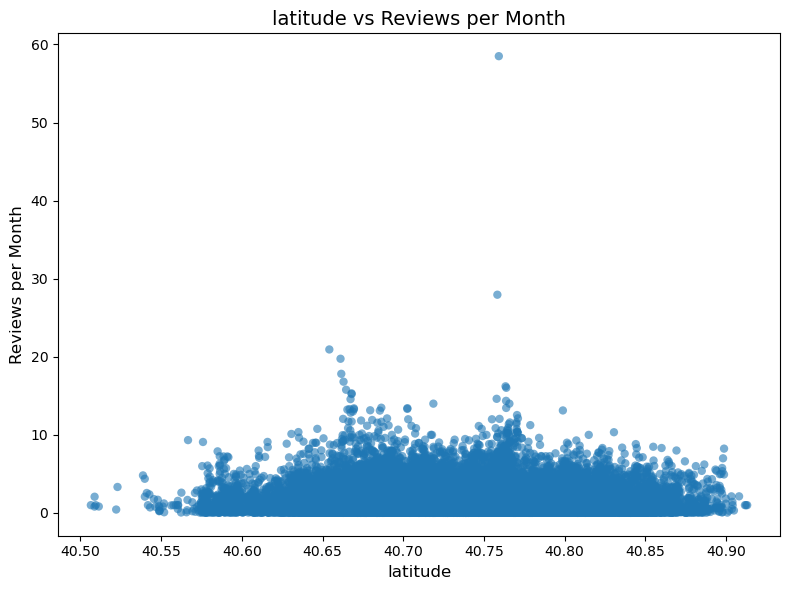

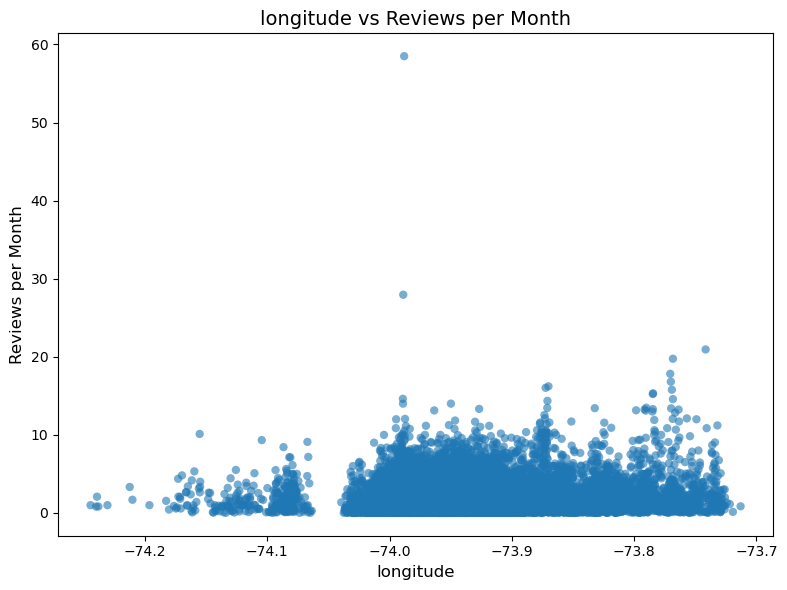

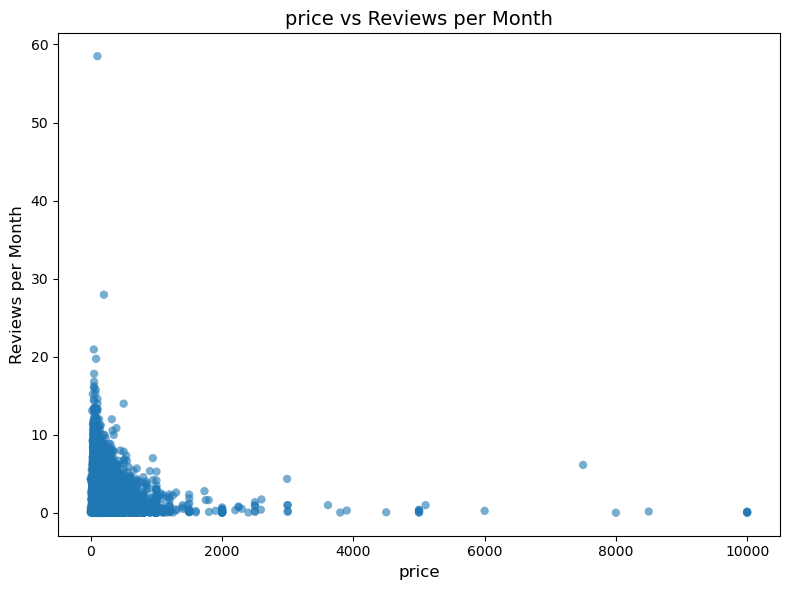

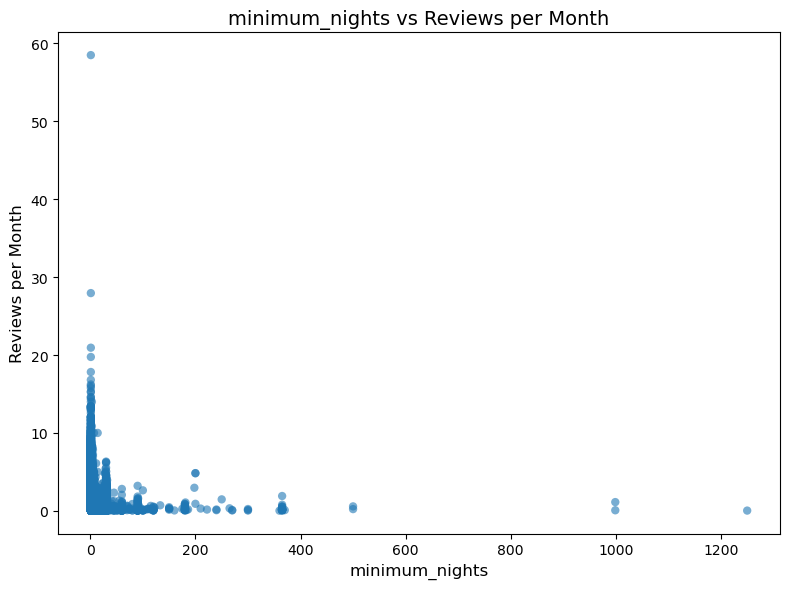

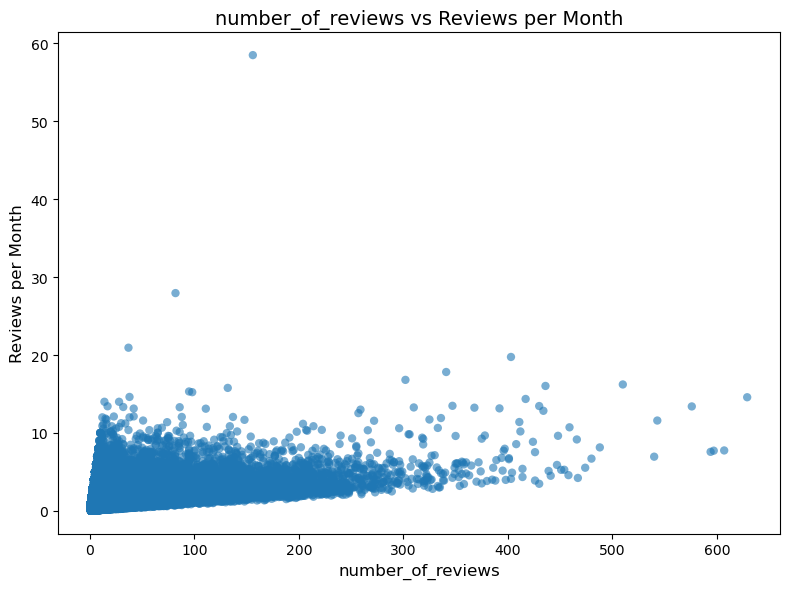

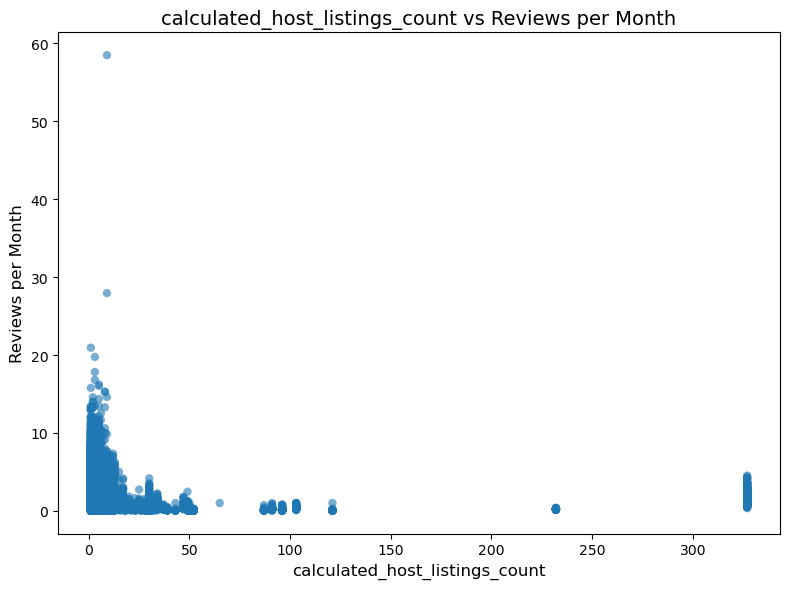

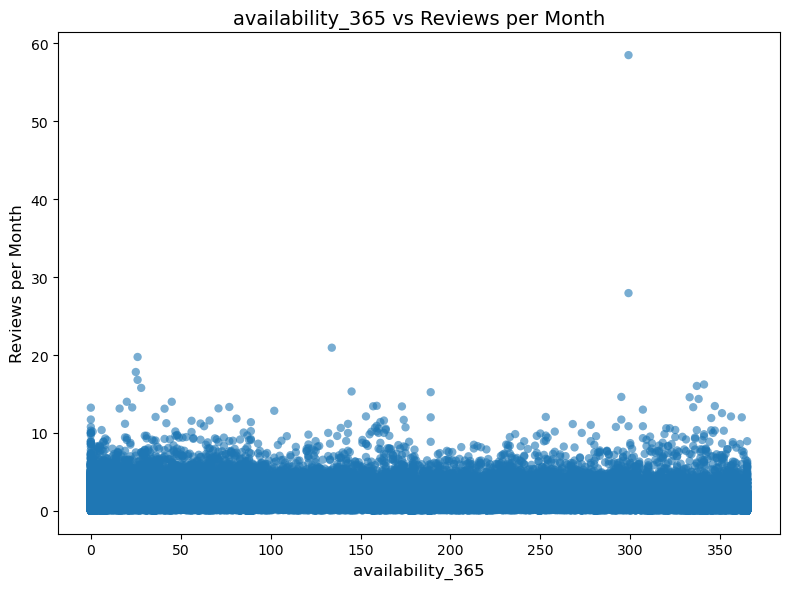

In [11]:
for col in numeric_cols: 
    plt.figure(figsize=(8,6))
    plt.scatter(
        airbnb_df[col],
        airbnb_df['reviews_per_month'],
        alpha=0.6, 
        edgecolors = 'none' 
    )
    plt.title(f'{col} vs Reviews per Month', fontsize = 14)
    plt.xlabel(col, fontsize = 12) 
    plt.ylabel('Reviews per Month', fontsize = 12)
    plt.tight_layout()
    plt.show()

### Latitude vs Reviews per Month
Latitude appears to have a quadratic relationship with reviews_per_month. Initially, as latitude increases, the number of reviews also increases. However, beyond approximately 40.77, further increases in latitude correspond to a decrease in reviews_per_month.

### Longtitude vs Reviews per Month
Listings with longtitudes between roughly -74.05 and -73.73 tend to have similar reviews_per_month, ranging between 0 to 8 reviews.

### price vs Reviews per Month
Lower-priced listings generally have higher reviews_per_month. The distribution of price is right-skewed, indicating many listings at lower price points and fewer at higher prices.  

### minimum_nights vs Reviews per Month
Listings with a lower minimum number of nights tend to receive more reviews per month. This feature is also right-skewed, with most listings requiring fewer nights. 

### number of reviews vs Reviews per Month
The is no clear relationship between number_of_reviews and reviews_per_month. A high total number of reviews does not necessarily imply more reviews per month. 

### calculated_host_listings vs Reviews per Month
The number of listing sper host does not show a strong relationship with reviews_per_month. Hosts with more listings do not necessarily receive more reviews per month on each listing. 

### avilability_365 vs Reviews per Month
availability_365 appears to be constant with respect to reviews_per_month and does not provide meaningful variation in predicting popularity. 

## Evaluation Metric
Given that this is a regression problem, suitable evaluation metrics include Mean Squared Error (MSE), Root Mean Squared Error (RMSE), Mean Absolute Percentage Error (MAPE), and R^2. Since the goal is to predict the popularity of a lsiting through the target feature reviews_per_month, RMSE is likely the most appropriate metric for assessing the model performance. It is interpretable in the same units as the target and penalized large errors, emphasizing significant deviations. MAPE may not be suitable because reviews_per_month can be very close to 0, which would make the percentage errors misleading. MSE is less interpretable due to its squared units. R^2 can still be useful to quantify how much of the variance in the target variable is explained by the model. 

In [12]:
...

Ellipsis

In [13]:
...

Ellipsis

In [14]:
...

Ellipsis

In [15]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 4. Feature engineering
<hr>
rubric={points:1}

<div class="alert alert-info">
    
**Your tasks:**

1. **Perform feature engineering**: Create new features that are relevant to the problem and use this updated feature set in the following exercises. You may need to iterate between **feature engineering** and **preprocessing** to refine your features and improve model performance.
   
</div>

<div class="alert alert-warning">
    
Solution_4
    
</div>

_Points:_ 1

In [16]:
train_df.columns

Index(['id', 'name', 'host_id', 'host_name', 'neighbourhood_group',
       'neighbourhood', 'latitude', 'longitude', 'room_type', 'price',
       'minimum_nights', 'number_of_reviews', 'last_review',
       'reviews_per_month', 'calculated_host_listings_count',
       'availability_365'],
      dtype='object')

~~Different months of the year may correspond to varying levels of reviews_per_month. For example, during peak travel periods such as sumer break (May - August) or the Christmas holidays (December - January), listings may receive more bookings, resulting in higher reviews_per_month. Therefore, we will parse the last_review date to extract just the month of the last review as a feature.~~ 

In [17]:
# train_df['last_review'] = pd.to_datetime(train_df['last_review'])
# train_df['review_month'] = train_df['last_review'].dt.month
# train_df

In [18]:
# test_df['last_review'] = pd.to_datetime(test_df['last_review'])
# test_df['review_month'] = test_df['last_review'].dt.month
# test_df

Traveler's decisions to book an Airbnb may be influenced by how close the listing the city center, as proximity often affects convenience. Therefore, it could be valuable to create a new feature that calculates the distance of each listing from the city center using its latitude and longtitude. The coordinates of central Manhattan are longtitude -73.9794 and latitude 40.7639. 1 degree of latitude and longtitude is approximately 111km. Hence, I will be using the euclidean distance with factor 111 km per degree to calculate the distance from city center in kilometers. 

In [19]:
city_center = (40.7128, -73.9794)

lat_factor = 111
lon_factor = 111 * np.cos(np.radians(city_center[0]))

train_df['distance_to_center'] = np.sqrt(
    ((train_df['latitude'] - city_center[0]) * lat_factor)**2 + 
    ((train_df['longitude'] - city_center[1]) * lon_factor)**2 
)
train_df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,distance_to_center
36150,28736148,Cozy 1 Bedroom Apt in Hamilton Heights,43431867,Tommy,Manhattan,Washington Heights,40.83256,-73.94440,Entire home/apt,96,4,0,NaN,NaN,1,17,13.615623
45223,34613254,Amazing One Bedroom at the Time Square Area/72B,48146336,Irina,Manhattan,Hell's Kitchen,40.76134,-73.99299,Entire home/apt,150,30,0,NaN,NaN,20,332,5.507931
14316,11144496,"New Spacious Master, Williamsburg",48819868,Nick,Brooklyn,Williamsburg,40.71119,-73.95097,Private room,200,1,0,NaN,NaN,1,0,2.398674
1691,766814,Adorable Midtown West Studio!,4022922,Caitlin,Manhattan,Hell's Kitchen,40.75900,-73.99530,Entire home/apt,95,1,0,NaN,NaN,1,0,5.299818
20195,16162621,NEW! Exceptional 2BR/1BA Williamsburg Oasis,104781467,Russell,Brooklyn,Williamsburg,40.71306,-73.94856,Entire home/apt,199,3,1,2016-12-11,0.03,1,0,2.594938
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7763,5885201,SUNNY ROOM A IN CHARMING AREA :),4291007,Graham And Ben,Brooklyn,Bedford-Stuyvesant,40.69363,-73.95980,Private room,95,30,40,2019-06-01,0.80,11,331,2.692080
15377,12325045,IDEAL One bedroom apt by Central Park!,66501870,K Alexandra,Manhattan,Midtown,40.76016,-73.96910,Entire home/apt,139,2,132,2019-06-30,3.66,1,154,5.327911
17730,13915004,"Sunlit, spacious NY apartment",7177483,Dani,Manhattan,Harlem,40.80380,-73.95569,Entire home/apt,250,3,10,2019-01-01,0.28,1,0,10.296104
28030,21897845,One room.,159769278,Musieka,Bronx,Pelham Gardens,40.86706,-73.84674,Private room,40,2,17,2019-06-04,1.23,1,17,20.439501


In [20]:
city_center = (40.7128, -73.9794)

lat_factor = 111
lon_factor = 111 * np.cos(np.radians(city_center[0]))

test_df['distance_to_center'] = np.sqrt(
    ((test_df['latitude'] - city_center[0]) * lat_factor)**2 + 
    ((test_df['longitude'] - city_center[1]) * lon_factor)**2 
)
test_df

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,distance_to_center
29122,22367196,Sunny Bushwick Room with Holiday Sale Price!,163554531,Joshua,Brooklyn,Bushwick,40.69417,-73.91237,Private room,35,3,0,NaN,NaN,1,0,6.006862
2964,1725295,Midtwn E BEST LOCATION Priv Twin Rm 1 Loving Cat,215764,Lynn,Manhattan,Murray Hill,40.74740,-73.97847,Private room,85,1,135,2018-12-12,1.93,1,15,3.841397
14184,10938202,"Spacious, bright, living/bedroom",2455178,Nessa,Brooklyn,Flatbush,40.64145,-73.96642,Private room,55,5,6,2016-11-14,0.17,1,0,7.994792
1174,501693,Room w/pvt bathroom on Central Park,1490833,Patrick,Manhattan,Upper West Side,40.79520,-73.96240,Private room,99,1,280,2019-06-23,3.51,1,246,9.257562
42853,33270782,Spacious & Bright Brooklyn Getaway near trains,96240355,Sherika,Brooklyn,Bedford-Stuyvesant,40.67969,-73.90923,Private room,75,2,9,2019-06-24,2.62,1,0,6.954345
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
35599,28261992,Cute Room in Bushwick!,44545038,Oliver,Brooklyn,Bushwick,40.69510,-73.92981,Private room,48,3,5,2018-09-17,0.49,1,0,4.611776
40829,31714036,Urban Design Sanctuary,9582338,Max,Manhattan,NoHo,40.72626,-73.99316,Entire home/apt,250,3,9,2019-07-02,2.70,1,112,1.890115
39728,30914114,Beautiful and cozy street view 1BR in W Village,54501105,Sophie,Manhattan,West Village,40.73280,-74.00468,Entire home/apt,180,3,15,2019-06-08,2.68,2,166,3.074480
36220,28805003,"Micro-Studio in Hells Kitchen, Shared Bath",198861577,Novo,Manhattan,Hell's Kitchen,40.76021,-73.99197,Private room,69,30,0,NaN,NaN,5,0,5.367730


<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 5. Preprocessing and transformations
<hr>
rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Identify feature types**: Determine the different types of features in your dataset (e.g., numerical, categorical, ordinal, text) and specify the transformations you would apply to each type.

2. **Define a column transformer (if needed)**: Implement a `ColumnTransformer` to apply the appropriate preprocessing steps to each feature type.
 
</div>

<div class="alert alert-warning">
    
Solution_5
    
</div>

_Points:_ 10

Since some instances have missing target values, we will remove them from the dataset becuase models cannot be trained on unkown target vairables. Additionally, we will drop rows with missing values in the reviews_per_month feature, for simplicity. 

In [21]:
train_df = train_df.dropna(subset=['reviews_per_month'])
test_df = test_df.dropna(subset=['reviews_per_month'])
# train_df = train_df.dropna(subset=['review_month'])

In [22]:
train_df.shape

(27236, 17)

In [23]:
# Since id and host_id are simply identifiers, we can safely drop them.
# The latitude and longitude columns have already been used to calculate distance_to_center, 
# so they are no longer needed.
# The calculated_host_listings_count feature shows no direct relationship with 'reviews_per_month', 
# therefore it can also be removed. 
# name will also be dropped as it likely doesn't have as strong of a predictive power of the target 
# compared to the other values and requires extra preprocessing steps.
drop_feats = ['id', 'host_id', 'host_name', 'latitude', 'longitude', 'last_review', 'calculated_host_listings_count', 'name']
# The name column contains a descriptive text about the listing, which may be useful. 
categorical_feats = ['neighbourhood_group', 'neighbourhood', 'room_type']
numeric_feats = ['price', 'minimum_nights', 'number_of_reviews', 
                      'availability_365', 'distance_to_center']
target = ['reviews_per_month']

In [24]:
ct = ColumnTransformer( 
    transformers = [
    	("scaling", Pipeline([("imputer", SimpleImputer(strategy="mean")), ("scaler", StandardScaler())]), numeric_feats), # scaling on numeric features 
    	("onehot", OneHotEncoder(handle_unknown="ignore"), categorical_feats), # OHE on categorical features 
        # ("passthrough", "passthrough", passthrough_feats), # no transformations on the binary features
        ("drop", "drop", drop_feats) # drop the drop features 
    ]
)

In [25]:
ct

,transformers,"[('scaling', ...), ('onehot', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'mean'
,fill_value,None


In [26]:
X_train = train_df.drop(columns=['reviews_per_month'])
y_train = train_df['reviews_per_month']

X_test = test_df.drop(columns = ['reviews_per_month'])
y_test = test_df['reviews_per_month']

In [27]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 6. Baseline model
<hr>
rubric={points:2}

<div class="alert alert-info">
    
**Your tasks:**

1. **Establish a baseline**: Use one of `scikit-learn`’s baseline models (e.g., `DummyClassifier` or `DummyRegressor`, depending on your task) and report the results. This will serve as a reference point for evaluating the performance of your more advanced models.

</div>

<div class="alert alert-warning">
    
Solution_6
    
</div>

_Points:_ 2

In [28]:
baseline_model = Pipeline([
    ("preprocessor", ct), 
    ("model", DummyRegressor(strategy="mean"))
])

cv_scores = cross_val_score(
    baseline_model, 
    # X=train_df.drop(columns=target), 
    # y=train_df['reviews_per_month'],
    X_train, 
    y_train,
    cv=5, 
    scoring="neg_root_mean_squared_error"  
)

# Convert from negative to positive RMSE
cv_scores = -cv_scores

print(f"Cross-validated RMSE scores: {cv_scores}")
print(f"Mean CV Root Mean Squared Error: {cv_scores.mean():.2f}")

Cross-validated RMSE scores: [1.6945712  1.69121572 1.80603684 1.64286253 1.66436674]
Mean CV Root Mean Squared Error: 1.70


In [29]:
...

Ellipsis

In [30]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 7. Linear models 
<hr>
rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Train a linear model**: Use a linear model as your first real attempt at solving the problem.

2. **Tune hyperparameters**: Perform hyperparameter tuning to explore different values of the model's complexity parameter. 

3. **Evaluate with cross-validation**: Report the cross-validation scores along with their standard deviation.

4. **Summarize findings**: Summarize your results, highlighting key observations from your experiments.

</div>

<div class="alert alert-warning">
    
Solution_7
    
</div>

_Points:_ 10

Using Grid Search, we have found that the best alpha for the linear regression model using Ridge is 10. Using alpha = 10, the best cross-validation RMSE is 1.36958.

In [31]:
pipe = Pipeline([
    ("preprocessor", ct), 
    ("model", Ridge())
])

param_grid = {
    "model__alpha": [0.01, 0.1, 1, 10, 100] 
}

grid_search = GridSearchCV(pipe, 
                           param_grid, 
                           cv = 5, 
                           scoring = "neg_root_mean_squared_error", 
                           n_jobs = -1)

grid_search.fit(X_train, y_train)

cv_results = grid_search.cv_results_
mean_cv_score = -cv_results["mean_test_score"]
std_cv_score = cv_results["std_test_score"]

print("Best Alpha:", grid_search.best_params_['model__alpha'])
print("Cross-Validation Scores (Mean RMSE):", mean_cv_score)
print("Standard Deviation of CV Scores:", std_cv_score)
print("Best Cross-Validation RMSE:", -grid_search.best_score_)

Best Alpha: 10
Cross-Validation Scores (Mean RMSE): [1.37338695 1.37312125 1.37178424 1.3695808  1.37235368]
Standard Deviation of CV Scores: [0.0748486  0.07493076 0.07533329 0.07619101 0.07741394]
Best Cross-Validation RMSE: 1.3695808018918492


In [32]:
...

Ellipsis

In [33]:
...

Ellipsis

In [34]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 8. Different models
<hr>
rubric={points:12}

<div class="alert alert-info">
    
**Your tasks:**

1. **Experiment with additional models**: Train at least **three models** other than a linear model. Ensure that **at least one** of these models is a **tree-based ensemble model** (e.g., Random Forest, Gradient Boosting, or XGBoost).

2. **Compare and interpret results**: Summarize your findings in terms of **overfitting/underfitting** behavior and **fit/score times** for each model. Reflect on your results. Were you able to **outperform the linear model**?

</div>

<div class="alert alert-warning">
    
Solution_8
    
</div>

_Points:_ 12

_Type your answer here, replacing this text._

In [35]:
# pip install xgboost

In [36]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor 
from xgboost import XGBRegressor 

pipe_rf = make_pipeline(ct, RandomForestRegressor(random_state = 123))
pipe_gb = make_pipeline(ct, GradientBoostingRegressor(random_state = 123))
pipe_xgb = make_pipeline(ct, XGBRegressor(random_state=123, verbosity = 0))

regressors = {
    "Random Forest": pipe_rf,
    "Gradient Boosting": pipe_gb,
    "XGBoost": pipe_xgb
}

results = []

for name, model in regressors.items():
    scores = cross_validate(
        model, 
        X_train, 
        y_train, 
        scoring = "neg_root_mean_squared_error", 
        return_train_score = True, 
        n_jobs = -1
    )
    results.append({
        "Model": name,
        "Train RMSE": -np.mean(scores["train_score"]),  # use train_score
        "Test RMSE": -np.mean(scores["test_score"]),
        "Fit Time": np.mean(scores["fit_time"]),
        "Score Time": np.mean(scores["score_time"])
    })

results_df = pd.DataFrame(results).sort_values(by="Test RMSE") 
print(results_df)
    

               Model  Train RMSE  Test RMSE   Fit Time  Score Time
2            XGBoost    0.911864   1.162851   0.217307    0.020668
0      Random Forest    0.443449   1.172505  54.370444    0.218913
1  Gradient Boosting    1.123228   1.173333   2.231184    0.015007


Random Forest has a low RMSE on the training data but a significantly higher RMSE on the test data. This large gap indicates substantial overfitting, meaning the model performs well on the training set but does not generalize well on unseen data. XGBoost shows a smaller difference between training and test RMSE, suggesting less overfitting compared to Random Forest. Gradient Boosting has a lower difference in the RMSE values for both training and test sets, but its overall RMSE values are higher than those of Random Forest and XGBoost, indicating possible underfitting. Comparing our linear regression model using Ridge to these results, it has the highest test RMSE suggesting weak performance and the greatest predictive errors, again suggesting overfitting. Hence, XGBoost might be the best performing model for this dataset. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 9. Feature selection 
<hr>
rubric={points:2}

<div class="alert alert-info">
    
**Your tasks:**

1. **Perform feature selection**: Attempt to select relevant features using methods such as `RFECV` or forward selection.

2. **Evaluate the impact** Compare the model performance before and after feature selection. Do the results improve with feature selection?

3. **Summarize findings** Summarize your observations and decide whether to **keep feature selection** in your pipeline.  If it improves results, retain it for the next exercises; otherwise, you may choose to omit it.
</div>

<div class="alert alert-warning">
    
Solution_9
    
</div>

_Points:_ 2

_Type your answer here, replacing this text._

In [37]:
from sklearn.feature_selection import RFECV

# rfe_pipe = make_pipeline(
#     ct, 
#     RFECV(
#         estimator = Ridge(max_iter = 2000, random_state = 123), 
#         cv = 10, 
#         scoring = "neg_root_mean_squared_error", 
#         n_jobs = -1
#     )
# )

# scores = cross_validate(rfe_pipe, X_train, y_train, return_train_score = True, n_jobs = -1)
# results = pd.DataFrame(scores).mean()
# print(results)

X_train_transformed = ct.fit_transform(X_train) 
y_train_values = y_train.values 

rfe = RFECV(
        estimator = Ridge(max_iter = 2000, random_state = 123), 
        cv = 10, 
        scoring = "neg_root_mean_squared_error", 
        n_jobs = -1
)

rfe.fit(X_train_transformed, y_train_values) 

print("Optimal number of features:", rfe.n_features_)
print("Best CV score (RMSE):", -rfe.cv_results_['mean_test_score'].max())

Optimal number of features: 189
Best CV score (RMSE): 1.3685144986783164


In [38]:
X_train_transformed.shape

(27236, 228)

After applying RFECV on the preprocessed data, the model kept 189 of 229 features. The resulting test RMSE decreased from 1.36951 to 1.36851. This suggests an improvement in generalisation and less overfitting. 

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 10. Hyperparameter optimization
<hr>
rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Optimize hyperparameters**: Attempt to optimize hyperparameters for the models you have tried so far. In at least **one case**, tune **multiple hyperparameters** for a single model.

2. **Use suitable optimization methods**: You may use any of the following approaches for hyperparameter optimization:
   - [`GridSearchCV`](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html)  
   - [`RandomizedSearchCV`](http://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)  
   - [Bayesian optimization with scikit-optimize](https://github.com/scikit-optimize/scikit-optimize)

3. **Summarize your results**: Report and compare the optimized results across models. Discuss whether hyperparameter optimization led to performance improvements.

</div>

<div class="alert alert-warning">
    
Solution_10
    
</div>

_Points:_ 10

Based on the grid search results from part 7 Linear Models, the best alpha value for the Ridge model was 10. However, using a randomised search, it was determined that the optimal value for alpha is 18. Despite the difference, the model's performance remained nearly identical. The RMSE was 1.3695 for alpha = 10 and 1.3693 for alpha = 18. Therefore, the performance improvement from hyperparameter optimisation is negligible, suggesting that the model is relatively insensitive to small changes in the alpha value. 

In [39]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform 

pipe = Pipeline([
    ("preprocessor", ct), 
    ("model", Ridge())
])

param_distributions = {
    "model__alpha": uniform(0.01, 100)
}

random_search = RandomizedSearchCV(
    pipe, 
    param_distributions, 
    n_iter = 20, 
    cv = 5, 
    scoring = "neg_root_mean_squared_error", 
    n_jobs = -1, 
    random_state = 123
)

random_search.fit(X_train, y_train)

cv_results = random_search.cv_results_
mean_cv_score = -cv_results["mean_test_score"]
std_cv_score = cv_results["std_test_score"]

print("Best Alpha:", random_search.best_params_['model__alpha'])
print("Cross-Validation Scores (Mean RMSE):", mean_cv_score)
print("Standard Deviation of CV Scores:", std_cv_score)
print("Best Cross-Validation RMSE:", -random_search.best_score_)

Best Alpha: 18.25917304535
Cross-Validation Scores (Mean RMSE): [1.37108763 1.36947333 1.36936762 1.37045751 1.37118769 1.36992488
 1.37227619 1.37103599 1.37015571 1.36980633 1.36963745 1.37122853
 1.36998438 1.3700118  1.3698287  1.37126657 1.36933687 1.36934132
 1.37037279 1.37037403]
Standard Deviation of CV Scores: [0.07726761 0.07675329 0.07661553 0.07714376 0.07728319 0.0769978
 0.07740749 0.07726045 0.07707158 0.07695247 0.07687283 0.07728959
 0.07701542 0.0759398  0.07696212 0.07729578 0.07648331 0.07646204
 0.07712298 0.07712327]
Best Cross-Validation RMSE: 1.3693368730068811


In [40]:
...

Ellipsis

In [41]:
...

Ellipsis

In [42]:
...

Ellipsis

In [43]:
...

Ellipsis

In [44]:
...

Ellipsis

In [45]:
...

Ellipsis

In [46]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 11. Interpretation and feature importances
<hr>
rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Interpret model feature importance**: Use one of the interpretation methods discussed in class (e.g., `shap`), or another suitable method of your choice, to examine the most important features of one of your **non-linear models**.

2. **Summarize insights**: Summarize your observations about which features contribute most to the model's predictions and how they influence the outcomes.

   
</div>

<div class="alert alert-warning">
    
Solution_11
    
</div>

_Points:_ 10

_Type your answer here, replacing this text._

In [47]:
pipe_rf = make_pipeline(ct, RandomForestRegressor(random_state = 123))
pipe_rf.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('randomforestregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('scaling', ...), ('onehot', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [48]:
# pip install eli5

In [49]:
rf_model = pipe_rf.named_steps['randomforestregressor']
feature_names = ct.get_feature_names_out()

importances = pd.DataFrame({
    "feature": feature_names,
    "importance": rf_model.feature_importances_
}).sort_values("importance", ascending=False)

importances.head(15)

,feature,importance
2,scaling__number_of_reviews,0.376129
3,scaling__availability_365,0.159541
1,scaling__minimum_nights,0.105549
4,scaling__distance_to_center,0.093119
0,scaling__price,0.073079
198,onehot__neighbourhood_Theater District,0.022314
69,onehot__neighbourhood_East Elmhurst,0.010246
8,onehot__neighbourhood_group_Queens,0.008388
225,onehot__room_type_Entire home/apt,0.006595
104,onehot__neighbourhood_Hell's Kitchen,0.006355


scaling__number_of_reviews is the most influential feature in predicting the target using our Random Forest model. This suggests that listings with a higher number of reviews are likely more popular, which positively impacts the predicted values. The second most important feature, scaling__availability_365, indicates that listings available for more days throughout the year have a greater influence on the predicted reviews_per_month, likely reflecting how availability affects guest engagement and booking activity. 

In [50]:
...

Ellipsis

In [51]:
...

Ellipsis

In [52]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 12. Results on the test set
<hr>

rubric={points:10}

<div class="alert alert-info">
    
**Your tasks:**

1. **Evaluate on the test set**: Apply your best-performing model to the test data and report the test scores.

2. **Compare and reflect**: Compare the **test scores** with the **validation scores** from previous experiments. Discuss the consistency between them. How much do you **trust your results**? Reflect on whether you might have encountered **optimization bias**.

3. **Explain individual predictions**: Select one or two examples from your test predictions and use an interpretation method (e.g., **SHAP force plots**) to explain these individual predictions.
</div>

<div class="alert alert-warning">
    
Solution_12
    
</div>

_Points:_ 10

XGBoost returned the lowest test RMSE of 1.162851, making it the best-performing model. It also had the shortest fit time of 0.224 seconds and the fastest scoring time 0.020 seconds. This highlights that it has best accuracy and computational efficiency. 

In [53]:
pipe_xgb = make_pipeline(
    ct, 
    XGBRegressor(random_state = 123, eval_metric = "rmse")
)
pipe_xgb.fit(X_train, y_train)

,steps,"[('columntransformer', ...), ('xgbregressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('scaling', ...), ('onehot', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [54]:
pipe_xgb = Pipeline([
    ("preprocessor", ct),  
    ("model", XGBRegressor(random_state=123))
])

pipe_xgb.fit(X_train, y_train) 

y_pred_test = pipe_xgb.predict(X_test)

test_rmse = np.sqrt(mean_squared_error(y_test, y_pred_test))
test_r2 = r2_score(y_test, y_pred_test)

print(f"Test RMSE: {test_rmse:.3f}")
print(f"Test R^2: {test_r2:.3f}")

Test RMSE: 1.124
Test R^2: 0.526


In [55]:
scoring = {
    "rmse": make_scorer(root_mean_squared_error),
    "r2": "r2"
}

cv_results = cross_validate(pipe_xgb, X_train, y_train,
                            cv=5,
                            scoring=scoring,
                            return_train_score=True,
                            n_jobs=-1)

print("\nCross-Validation Training Metrics:")
print(f"Mean train RMSE: {cv_results['train_rmse'].mean():.3f}")
print(f"Mean train R^2: {cv_results['train_r2'].mean():.3f}")
print(f"Mean fit time: {cv_results['fit_time'].mean():.3f} sec")
print(f"Mean score time: {cv_results['score_time'].mean():.3f} sec")


Cross-Validation Training Metrics:
Mean train RMSE: 0.912
Mean train R^2: 0.712
Mean fit time: 0.186 sec
Mean score time: 0.018 sec


In [56]:
...

Ellipsis

In [57]:
...

Ellipsis

In [58]:
...

Ellipsis

In [59]:
...

Ellipsis

In [60]:
...

Ellipsis

In [61]:
...

Ellipsis

In [62]:
...

Ellipsis

In [63]:
...

Ellipsis

In [64]:
...

Ellipsis

<!-- END QUESTION -->

<br><br>

<!-- BEGIN QUESTION -->

## 13. Summary of results
<hr>
rubric={points:12}

Imagine you are preparing to present the summary of your results to your boss and co-workers.

<div class="alert alert-info">
    
**Your tasks:**

1. **Summarize key results**: Create a clear and concise table highlighting your most important results (e.g., models compared, validation/test scores, key observations).

2. **Write concluding remarks**: Summarize your main takeaways from the project, including what worked well and what did not.

3. **Propose future improvements**: Discuss ideas or approaches you did not try but that could potentially improve **performance** or **interpretability**.

4. **Report final results**: Report your **final test score** and the **metric** you used.

</div>


<div class="alert alert-warning">
    
Solution_13
    
</div>

_Points:_ 12

**Below are the results of all the models we tested.**

In [65]:
data = {
    "Model": ["Ridge Regression", "Random Forest", "Gradient Boosting", "XGBoost", "XGB Test Set"],
    "Train RMSE": [None, 0.443449, 1.123228, 0.911864, 0.912],
    "Test RMSE": [1.370, 1.172505, 1.173333, 1.162851, 1.124],
    "Train R^2": [None, None, None, None, 0.712],
    "Test R^2": [None, None, None, None, 0.526],
    "Fit Time": [None, 52.720680, 2.311249, 0.164428, 0.248],
    "Score Time": [None, 0.199318, 0.015074, 0.018236, 0.023]
}

results_df = pd.DataFrame(data)

results_df = results_df.sort_values(by="Test RMSE").reset_index(drop=True)

results_df


,Model,Train RMSE,Test RMSE,Train R^2,Test R^2,Fit Time,Score Time
0,XGB Test Set,0.912000,1.124000,0.712,0.526,0.248000,0.023000
1,XGBoost,0.911864,1.162851,NaN,NaN,0.164428,0.018236
2,Random Forest,0.443449,1.172505,NaN,NaN,52.720680,0.199318
3,Gradient Boosting,1.123228,1.173333,NaN,NaN,2.311249,0.015074
4,Ridge Regression,NaN,1.370000,NaN,NaN,NaN,NaN


Based on these results, the best model for the New York Airbnb dataset is XGBoost, with a test RMSE of 1.124 and test R^2 0.0526. Random Forest and Gradient Boosting performed similarly, with test RMSEs around 1.17. 

Throughout this assignment, I learned the critical importance of feature preprocessing to ensure clean, usable data. Improper preprocessing can lead to issues during feature importance analysis and hyperparameter optimisation. Testing different models showed that, although ensemble tree methods are more complex, they generally achieve better performance, making the tradeoff worthwhile when accuracy improves significantly. 

Even after hyperparameter optimisation and feature selection, there were no  substantial improvements in performance, suggesting that the current feature set and model choice capture most of the predictive signal. 

For future improvements, I plan to perform more extensive hyperparameter tuning for XGBoost and use SHAP and ELI5 to gain a deeper understanding of feature importances and model interpretability. 

<!-- END QUESTION -->

<br><br>

<br><br>

<!-- BEGIN QUESTION -->

## 14. Your takeaway
<hr>
rubric={points:2}

<div class="alert alert-info">
    
**Your tasks:**

What is your biggest takeaway from the supervised machine learning material we have learned so far? Please write thoughtful answers.  

</div>

<div class="alert alert-warning">
    
Solution_14
    
</div>

_Points:_ 2

The biggest takeaway I have learned from the supervised machine learning material so far is the importance of data preprocessing. Data that is not properly preprocessed at the start can significantly affect model performance and create problems throughout the workflow. While working on the assignment, I frequently encountered issues due to insufficient preprocessing, which required me to review and refine my column transformers and pipelines to ensure that later steps in model building and optimization would run smoothly. 

<!-- END QUESTION -->

<br><br>

Before submitting your assignment, please ensure you have followed all the steps in the **Instructions** section at the top.  

### Submission checklist  

- [ ] Restart the kernel and run all cells (▶▶ button)
- [ ] Make sure to push the most up to date version of your homework assignment to your GitHub repository so that we can use it for grading if there are any problems with your submission on Gradescope. 
- [ ] The `.ipynb` file runs without errors and shows all outputs.  
- [ ] Only the `.ipynb` file and required output files are uploaded (no extra files).  
- [ ] If the `.ipynb` file is too large to render on Gradescope, upload a Web PDF and/or HTML version as well.


This was a tricky one but you did it 👏👏!  

![](img/eva-well-done.png)